# 03 · Explainability Methods

**Objective.** Generate and inspect Grad-CAM, Integrated Gradients, and Occlusion Sensitivity maps for a fixed checkpoint, and document their normalization and visualization conventions.

## Methods

### Grad-CAM (Selvaraju et al., 2017)

For target class $c$ and convolutional feature map $A^k$,

$$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A_{ij}^k}, \qquad L^c = \mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right).$$

The map is bilinearly upsampled to $224\times224$ and min–max normalized.

### Integrated Gradients (Sundararajan et al., 2017)

$$\mathrm{IG}_i(x) = (x_i - x'_i)\int_0^1 \frac{\partial f(x' + \alpha(x-x'))}{\partial x_i}\,d\alpha,$$

approximated with a Riemann sum (`steps = 16`) and a zero baseline. Absolute attributions are summed over color channels and normalized.

### Occlusion Sensitivity (Zeiler & Fergus, 2014)

A $32\times32$ patch slides with stride 16. Each patch is replaced by the normalized zero value, and the drop in the predicted-class probability is written back to the patch. Overlapping contributions are averaged.

> **Normalization caveat.** All maps are min–max normalized per sample. They are **relative saliency maps**, not calibrated probabilities or causal effects. Comparisons therefore concern spatial agreement, not absolute importance.

## Checkpoint and target layer

Grad-CAM hooks the last residual block (`model.layer4[-1]`), the deepest layer with spatial resolution $7\times7$ before global pooling. Integrated Gradients and Occlusion operate directly on the input. The model is fixed in evaluation mode; no weights are updated.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage, display

from src.config import ExperimentConfig
from src.data.oxford_pets import IMAGENET_MEAN, IMAGENET_STD, load_oxford_pets
from src.explainers.methods import GradCAM, integrated_gradients, occlusion_sensitivity
from src.models.resnet import build_resnet18
from src.utils import device, seed_everything

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300})

config = ExperimentConfig()
config.create_directories()
seed_everything(config.seed)

checkpoint_path = config.checkpoint_root / "resnet18_best.pth"
if not checkpoint_path.exists():
    raise FileNotFoundError("Checkpoint missing. Run notebook 02 or `python -m src.train` first.")

model = build_resnet18(config.num_classes)
state = torch.load(checkpoint_path, map_location=device())
model.load_state_dict(state["model_state_dict"])
model.to(device()).eval()
print(f"Loaded checkpoint: {checkpoint_path}")
print(f"Device: {device()}")

Loaded checkpoint: checkpoints\resnet18_best.pth
Device: cpu


## Sample selection

A deterministic batch is taken from the official test split. The same samples are used throughout this notebook so that method comparisons are paired.

In [2]:
_, _, test_loader = load_oxford_pets(
    config.data_root, config.image_size, config.batch_size, config.num_workers, seed=config.seed
)

NUM_SAMPLES = 4
images, labels = next(iter(test_loader))
images = images[:NUM_SAMPLES].to(device())
labels = labels[:NUM_SAMPLES]
print(f"Selected {images.size(0)} samples with labels {labels.tolist()}")

Selected 4 samples with labels [0, 0, 0, 0]


## Build explainers

Each explainer maps a batch of normalized images to a batch of `1 × H × W` normalized attribution maps. Occlusion is the most expensive method because it performs many forward passes.

In [3]:
grad_cam = GradCAM(model, model.layer4[-1])

explainers = {
    "Grad-CAM": lambda batch: grad_cam(batch),
    "Integrated Gradients": lambda batch: integrated_gradients(model, batch, steps=16),
    "Occlusion": lambda batch: occlusion_sensitivity(model, batch, patch_size=32, stride=16),
}
list(explainers)

['Grad-CAM', 'Integrated Gradients', 'Occlusion']

## Generate maps

All maps are computed for the predicted class, which is the default behaviour of each implementation. No target labels are forced, so the maps explain the model's own decision rather than the ground truth.

In [4]:
maps_by_method = {name: explain(images).detach().cpu() for name, explain in explainers.items()}
for name, maps in maps_by_method.items():
    print(f"{name:>22}: shape={tuple(maps.shape)} | min={maps.min():.3f} | max={maps.max():.3f}")

              Grad-CAM: shape=(4, 1, 224, 224) | min=0.000 | max=1.000
  Integrated Gradients: shape=(4, 1, 224, 224) | min=0.000 | max=1.000
             Occlusion: shape=(4, 1, 224, 224) | min=0.000 | max=1.000


## Visual comparison

The original image is shown with the attribution overlaid using a semi-transparent colormap. Red regions indicate higher relative importance. The visual comparison is qualitative; Notebook 04 quantifies stability.

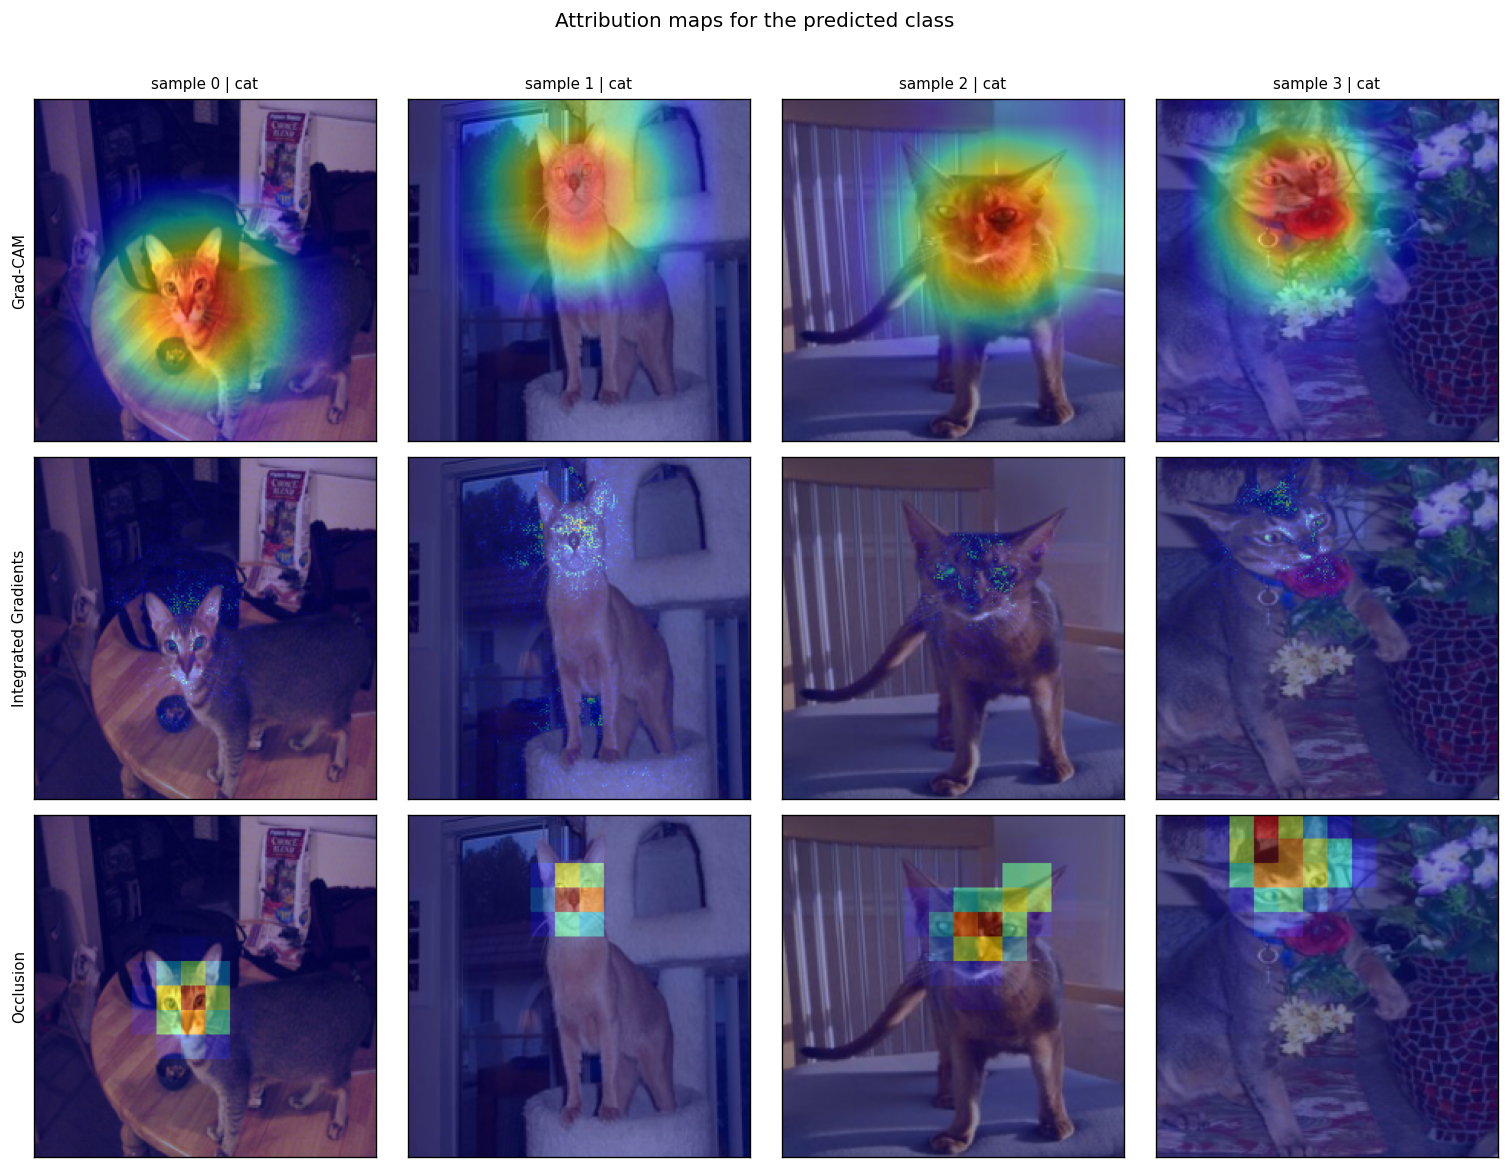

In [5]:
def denormalize_tensor(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
    return (tensor.detach().cpu() * std + mean).clamp(0, 1)

display_images = denormalize_tensor(images)
method_names = list(maps_by_method)

figure, axes = plt.subplots(
    len(method_names), NUM_SAMPLES,
    figsize=(3.2 * NUM_SAMPLES, 3.2 * len(method_names)),
)
for row, method_name in enumerate(method_names):
    for column in range(NUM_SAMPLES):
        axis = axes[row, column]
        axis.imshow(display_images[column].permute(1, 2, 0).numpy())
        axis.imshow(maps_by_method[method_name][column, 0].numpy(), cmap="jet", alpha=0.45, vmin=0, vmax=1)
        axis.set_xticks([])
        axis.set_yticks([])
        if row == 0:
            axis.set_title(f"sample {column} | {['cat', 'dog'][int(labels[column])]}", fontsize=9)
    axes[row, 0].set_ylabel(method_name, fontsize=9)

figure.suptitle("Attribution maps for the predicted class", y=1.01)
figure.tight_layout()
figure.savefig(Path("figures") / "explanation_methods_grid.png", dpi=300, bbox_inches="tight")
plt.show()

## Map statistics

Because maps are normalized, absolute activation levels are not comparable across methods. The high-activation share still provides a useful description of how spatially concentrated each method is.

In [6]:
stats_rows = []
for method_name, maps in maps_by_method.items():
    values = maps[:, 0].numpy()
    stats_rows.append({
        "method": method_name,
        "mean_activation": float(values.mean()),
        "std_activation": float(values.std()),
        "high_activation_share": float((values >= 0.5).mean()),
        "peak_activation": float(values.max()),
    })

stats_table = pd.DataFrame(stats_rows)
stats_table.to_csv(config.output_root / "explanation_map_statistics.csv", index=False)
stats_table

,method,mean_activation,std_activation,high_activation_share,peak_activation
0,Grad-CAM,0.200367,0.250637,0.150067,1.0
1,Integrated Gradients,0.018205,0.038211,0.000543,1.0
2,Occlusion,0.039131,0.137978,0.028061,1.0


## Export maps for reproducibility

The selected batch, labels, and attribution maps are saved as a compressed NumPy archive. This allows later inspection without recomputing gradients or occlusion sweeps.

In [7]:
archive_path = config.output_root / "explanation_maps_sample.npz"
np.savez_compressed(
    archive_path,
    images=images.detach().cpu().numpy(),
    labels=labels.numpy(),
    **{
        name.replace(" ", "_").replace("-", "_").lower(): maps.numpy()
        for name, maps in maps_by_method.items()
    },
)
print(f"Saved {archive_path} ({archive_path.stat().st_size / 1e6:.2f} MB)")

Saved experiments\results\explanation_maps_sample.npz (1.90 MB)


## Interpreting the maps

- **Agreement across methods** suggests that the model relies on a spatially consistent region. Disagreement is informative: gradient methods emphasize local sensitivity, whereas occlusion measures local predictive dependence.
- **Background activation** should be treated cautiously. A map that highlights context may reflect dataset bias rather than object evidence.
- **No ground-truth explanation exists.** These maps are hypotheses about model behaviour. Notebook 04 tests whether they are stable under semantically mild input changes, and Notebook 05 aggregates that stability.
- **Sanity checks** (Adebayo et al., 2018) are recommended before strong claims. Model-parameter randomization and data-order randomization are outside the scope of this notebook.

## References

- Selvaraju, R. R., et al. (2017). Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization. *ICCV*.
- Sundararajan, M., Taly, A., & Yan, Q. (2017). Axiomatic Attribution for Deep Networks. *ICML*.
- Zeiler, M. D., & Fergus, R. (2014). Visualizing and Understanding Convolutional Networks. *ECCV*.
- Adebayo, J., et al. (2018). Sanity Checks for Saliency Maps. *NeurIPS*.

Proceed to `04_explanation_stability.ipynb`.